# Augmentation of the isotropic hardening slot on cyclic tests of a structural steel

This notebook illustrates the augmentation strategy of hybridization, in which a
phenomenological slot is complemented by a neural correction, and the end-to-end calibration of
the resulting model through an implicit, history-dependent constitutive update, on experimental
cyclic data.

The model is the Voce-Chaboche (VC) model of metal plasticity, with nonlinear isotropic hardening
and two Armstrong-Frederick backstresses. Structural steels display a yield plateau at first
loading, followed by a smaller elastic domain and cyclic hardening in the subsequent cycles. A
monotone isotropic hardening cannot represent both: calibrated on cyclic data, the VC model
underestimates the initial yield stress. Hartloper et al. (2021) addressed this by adding a
hand-crafted term $-D_\infty(1 - e^{-ap})$ to the isotropic hardening (updated Voce-Chaboche
model, UVC). Here, the correction is learned from the data, without prescribing its form. The
isotropic hardening slot $R : p \mapsto R(p)$ thus has two implementations:

1. **VC:** $R(p) = Q_\infty\,(1 - e^{-bp})$;
2. **Augmented VC:** $R(p) = Q_\infty\,(1 - e^{-bp}) + \Delta R_{\boldsymbol\theta}(p)$, where
   $\Delta R_{\boldsymbol\theta}$ is a small neural network.

In [1]:
import equinox as eqx
import jax
import jax.numpy as jnp
import matplotlib.pyplot as plt
import numpy as np
import optimistix as optx
import pandas as pd
import paramax

import jaxmat
from jaxmat.parameters import Positive
from jaxmat.tensors.utils import FischerBurmeister as FB
from jaxmat.utils import partition_by_node_names

print(
    f"jaxmat {jaxmat.__version__}, jax {jax.__version__}, float64: {jax.config.jax_enable_x64}"
)

# Colours and line styles of the models
STYLE = {
    "VC": dict(
        color="darkorange", ls="--", zorder=3
    ),  # drawn on top where the models coincide
    "Augmented VC": dict(color="royalblue", ls="-"),
}

jaxmat 0.1, jax 0.10.2, float64: True


## Data

The data are the two cyclic uniaxial tests on a structural steel distributed as examples with
RESSPyLab (de Castro e Sousa et al., MIT license), given as true stress versus true strain. A
database of such coupon tests on structural steels is available on Zenodo (Hartloper et al.,
2022, doi:10.5281/zenodo.6965147).

- **Calibration test** (`example_1.csv`): constant-amplitude cycles at $\pm 2\%$.
- **Validation test** (`example_2.csv`): a variable-amplitude history up to $\pm 3\%$,
  representative of seismic loading, not used for calibration.

In [2]:
def load(filename):
    data = np.genfromtxt(filename, delimiter=",", skip_header=1)
    return jnp.asarray(data[:, 0]), jnp.asarray(data[:, -1])


tests = {"Calibration": load("example_1.csv"), "Validation": load("example_2.csv")}
for name, (eps, sig) in tests.items():
    print(
        f"{name:12s} {len(eps)} points, strain range [{float(eps.min()):.3f}, "
        f"{float(eps.max()):.3f}], accumulated strain {float(jnp.abs(jnp.diff(eps)).sum()):.2f}"
    )

Calibration  634 points, strain range [-0.020, 0.020], accumulated strain 0.90
Validation   1087 points, strain range [-0.031, 0.030], accumulated strain 0.28


## Model

Under uniaxial stress, von Mises plasticity with isotropic elasticity reduces exactly to a
one-dimensional model, with the stress $\sigma = E(\varepsilon - \varepsilon^p)$, the yield
function and the backstress evolution

$$
f = |\sigma - \textstyle\sum_k \alpha_k| - \sigma_{y,0} - R(p) \leq 0, \qquad
\dot\alpha_k = C_k\,\dot\varepsilon^p - \gamma_k\,\alpha_k\,\dot p, \qquad
\dot p = |\dot\varepsilon^p|.
$$

The time integration follows RESSPyLab: the flow direction $s$ is that of the trial relative
stress, the backstresses are integrated exactly over the increment for this direction,
$\alpha_k^{n+1} = s\,C_k/\gamma_k + (\alpha_k^n - s\,C_k/\gamma_k)\,e^{-\gamma_k\Delta p}$, and
the increment $\Delta p$ solves the yield condition. The complementarity conditions are written
with the Fischer-Burmeister function and solved by Newton's method (`optimistix`). The update is
thus an implicit module, differentiated by the implicit function theorem.

The model is an `equinox` module whose fields are the Young modulus, the initial yield stress,
the isotropic hardening module and the backstress parameters. Any module mapping $p$ to $R(p)$,
with $R(0) = 0$, can be used as the isotropic hardening module.

In [3]:
class UniaxialVoceChaboche(eqx.Module):
    E: jax.Array
    sig0: jax.Array = Positive()
    isotropic: eqx.Module
    C: jax.Array = Positive()
    gamma: jax.Array = Positive()

    def update(self, deps, state):
        """Return mapping over a strain increment; state = (stress, backstresses, p)."""
        sig, alpha, p = state
        sig_trial = sig + self.E * deps
        s = jnp.sign(sig_trial - jnp.sum(alpha))
        s = jnp.where(s == 0, 1.0, s)
        alpha_sat = s * self.C / self.gamma

        def backstresses(dp):
            return alpha_sat + (alpha - alpha_sat) * jnp.exp(-self.gamma * dp)

        def yield_function(dp):
            sig_new = sig_trial - self.E * s * dp
            return (
                s * (sig_new - jnp.sum(backstresses(dp)))
                - self.sig0
                - self.isotropic(p + dp)
            )

        # initial guess: linearized return mapping, away from the kink of FB at dp = 0
        f0 = yield_function(0.0)
        slope = (
            self.E
            + jax.grad(self.isotropic)(p)
            + jnp.sum(self.C - s * self.gamma * alpha)
        )
        dp0 = jnp.where(
            (f0 > 0) & (slope > 0), f0 / jnp.where(slope > 0, slope, 1.0), 0.0
        )
        sol = optx.root_find(
            lambda dp, _: FB(-yield_function(dp) / self.E, dp),
            optx.Newton(rtol=1e-10, atol=1e-12),
            dp0,
            adjoint=optx.ImplicitAdjoint(),
            max_steps=50,
            throw=False,
        )
        dp = sol.value
        return sig_trial - self.E * s * dp, backstresses(dp), p + dp


@eqx.filter_jit
def simulate(model, eps):
    """Stress and cumulated plastic strain along a strain history."""
    model = paramax.unwrap(model)

    def step(state, deps):
        state = model.update(deps, state)
        return state, (state[0], state[2])

    state0 = (jnp.zeros(()), jnp.zeros_like(model.C), jnp.zeros(()))
    _, (sig, p) = jax.lax.scan(step, state0, jnp.diff(eps))
    return jnp.concatenate([jnp.zeros(1), sig]), jnp.concatenate([jnp.zeros(1), p])

## Two implementations of the isotropic hardening slot

**VC.** All parameters are declared positive (`Positive`).

**Augmented VC.** The correction is a perceptron with one hidden layer of 3 tanh units (10
weights), evaluated on a logarithmic rescaling of the cumulated plastic strain:

$$
\Delta R_{\boldsymbol\theta}(p) = R_\text{c}\,\bigl[\mathcal{N}_{\boldsymbol\theta}(x(p))
- \mathcal{N}_{\boldsymbol\theta}(0)\bigr], \qquad
x(p) = \frac{\ln(1 + p/p_0)}{\ln(1 + p_\text{max}/p_0)},
$$

with $p_0 = 0.01$, $p_\text{max} = 1$ and $R_\text{c} = 100$ MPa, so that
$\Delta R_{\boldsymbol\theta}(0) = 0$. The size of the yield surface varies most rapidly just
after first yielding, at small values of $p$, whereas the calibration test reaches much larger
values of $p$. In the variable $x$, the transitions of the three hidden units, initially placed
at regular intervals of $[0, 1]$, cover several decades of $p$, so that the correction can
represent both regimes. The output layer is initialized to zero, so that training starts from
the VC model. The correction is not constrained in sign or monotonicity.

In [4]:
class Voce(eqx.Module):
    Q: jax.Array = Positive()
    b: jax.Array = Positive()

    def __call__(self, p):
        return self.Q * (1.0 - jnp.exp(-self.b * p))


p0, p_max, R_c, width = 0.01, 1.0, 100.0, 3


class AugmentedVoce(eqx.Module):
    voce: Voce
    correction: eqx.nn.MLP

    def delta(self, p):
        x = jnp.log1p(p / p0) / jnp.log1p(p_max / p0)
        return R_c * (self.correction(x) - self.correction(0.0))

    def __call__(self, p):
        return self.voce(p) + self.delta(p)


def make_correction(key):
    net = eqx.nn.MLP(
        "scalar", "scalar", width_size=width, depth=1, activation=jnp.tanh, key=key
    )
    steepness, centers = 10.0, jnp.linspace(0.0, 1.0, width)
    net = eqx.tree_at(
        lambda n: n.layers[0].weight, net, jnp.full((width, 1), steepness)
    )
    net = eqx.tree_at(lambda n: n.layers[0].bias, net, -steepness * centers)
    net = eqx.tree_at(lambda n: n.layers[1].weight, net, jnp.zeros((1, width)))
    return eqx.tree_at(lambda n: n.layers[1].bias, net, jnp.zeros(()))

## Calibration

The error measure is that of RESSPyLab: the squared stress error weighted by the strain
increments, normalized by the same weighting of the squared measured stress,

$$
\varphi(\boldsymbol\theta) = \frac{\sum_i |\Delta\varepsilon_i|\,
\bigl[(\sigma_i - \sigma_i^\text{exp})^2 + (\sigma_{i-1} - \sigma_{i-1}^\text{exp})^2\bigr]}
{\sum_i |\Delta\varepsilon_i|\,\bigl[(\sigma_i^\text{exp})^2 + (\sigma_{i-1}^\text{exp})^2\bigr]},
$$

which does not depend on the density of the data points along the history. The Young modulus is
fixed at its nominal value $E = 200$ GPa (partial calibration with
`jaxmat.utils.partition_by_node_names`); all other parameters are calibrated on the calibration
test only. For the augmented model, a weight decay
$\lambda\,\|\boldsymbol\theta_\text{NN}\|_2^2/n_\text{NN}$ with $\lambda = 10^{-6}$ is added to
the loss. Both models are calibrated by BFGS. The VC model is calibrated first, and its solution
is the initial point of the augmented model.

The gradient of the loss is obtained by reverse-mode automatic differentiation through the
sequence of implicit updates (`jax.lax.scan`), each update being differentiated by the implicit
function theorem.

In [5]:
E_nominal = 200e3
gamma_wd = 1e-6  # weight decay (lambda in the text)


def phi(sig_model, eps, sig_exp):
    w = jnp.abs(jnp.diff(eps))
    err = jnp.sum(
        w * ((sig_model[1:] - sig_exp[1:]) ** 2 + (sig_model[:-1] - sig_exp[:-1]) ** 2)
    )
    ref = jnp.sum(w * (sig_exp[1:] ** 2 + sig_exp[:-1] ** 2))
    return err / ref


def weight_decay(model):
    if not isinstance(model.isotropic, AugmentedVoce):
        return 0.0
    leaves = jax.tree.leaves(
        eqx.filter(model.isotropic.correction, eqx.is_inexact_array)
    )
    return sum(jnp.sum(x**2) for x in leaves) / sum(x.size for x in leaves)


def calibrate(model, max_steps=3000):
    params, static = partition_by_node_names(model, ["E"])
    eps, sig_exp = tests["Calibration"]

    def loss(params, args=None):
        model = eqx.combine(params, static)
        return phi(simulate(model, eps)[0], eps, sig_exp) + gamma_wd * weight_decay(
            model
        )

    sol = optx.minimise(
        loss, optx.BFGS(rtol=1e-8, atol=1e-10), params, max_steps=max_steps, throw=False
    )
    print(
        f"BFGS iterations: {int(sol.stats['num_steps'])}, "
        f"converged: {sol.result == optx.RESULTS.successful}"
    )
    return eqx.combine(sol.value, static)


vc_initial = UniaxialVoceChaboche(
    E=jnp.asarray(E_nominal),
    sig0=355.0,
    isotropic=Voce(Q=100.0, b=10.0),
    C=jnp.array([20000.0, 2000.0]),
    gamma=jnp.array([200.0, 20.0]),
)

In [6]:
models = {"VC": calibrate(vc_initial)}
models["Augmented VC"] = calibrate(
    eqx.tree_at(
        lambda m: m.isotropic,
        models["VC"],
        AugmentedVoce(models["VC"].isotropic, make_correction(jax.random.key(0))),
    )
)
models = {name: paramax.unwrap(m) for name, m in models.items()}
# stress and cumulated plastic strain of each model on each test
responses = {
    name: {test: simulate(m, eps) for test, (eps, _) in tests.items()}
    for name, m in models.items()
}

BFGS iterations: 109, converged: True
BFGS iterations: 1053, converged: True


## Results

The table reports the identified parameters and the error measure $\varphi$ on the calibration
and validation tests. For the augmented model, $Q_\infty$ and $b$ are those of its Voce part.

In [7]:
def n_trainable(model):
    params, _ = partition_by_node_names(model, ["E"])
    return int(
        sum(x.size for x in jax.tree.leaves(eqx.filter(params, eqx.is_inexact_array)))
    )


rows = []
for name, m in models.items():
    iso = m.isotropic.voce if isinstance(m.isotropic, AugmentedVoce) else m.isotropic
    errors = {
        test: 100 * float(phi(responses[name][test][0], eps, sig))
        for test, (eps, sig) in tests.items()
    }
    rows.append(
        {
            "Model": name,
            "Parameters": n_trainable(m),
            "σ_y,0 [MPa]": f"{float(m.sig0):.0f}",
            "Q∞ [MPa]": f"{float(iso.Q):.0f}",
            "b": f"{float(iso.b):.1f}",
            "C₁, C₂ [GPa]": ", ".join(f"{1e-3 * c:.1f}" for c in np.asarray(m.C)),
            "γ₁, γ₂": ", ".join(f"{g:.0f}" for g in np.asarray(m.gamma)),
            "φ calibration [%]": f"{errors['Calibration']:.3f}",
            "φ validation [%]": f"{errors['Validation']:.3f}",
        }
    )
table = pd.DataFrame(rows)
print(table.to_string(index=False))
table.to_csv("results.csv", index=False)

       Model  Parameters σ_y,0 [MPa] Q∞ [MPa]    b C₁, C₂ [GPa]  γ₁, γ₂ φ calibration [%] φ validation [%]
          VC           7         180       86 12.8  100.9, 10.6 928, 92             0.288            0.690
Augmented VC          17         361      120 28.5   99.0, 10.3 877, 90             0.255            0.612


Each figure below is also saved as a PDF and a PNG file. Experimental points of the calibration
test are shown as solid markers, those of the held-out validation test as open markers.

In [38]:
def stress_strain_plot(test, sl, filename):
    eps, sig = tests[test]
    fig, ax = plt.subplots()
    ax.plot(
        eps[sl],
        sig[sl],
        "o",
        color="crimson",
        mfc="none" if test == "Validation" else "crimson",
        label=f"{test} test",
    )
    for name, style in STYLE.items():
        ax.plot(eps[sl], responses[name][test][0][sl], lw=2.0, label=name, **style)
    ax.set_xlabel(r"True strain $\varepsilon$")
    ax.set_ylabel(r"True stress $\sigma$ [MPa]")
    ax.set_ylim(-700.0, 700.0)
    ax.legend(loc="upper left")
    for ext in ("pdf", "png"):
        fig.savefig(f"{filename}.{ext}", bbox_inches="tight")
    plt.show()


first_cycle = slice(
    0, 95
)  # calibration: first loading, first reversal and reloading to +2%
first_excursions = slice(
    100, 260
)  # validation: first loading to +1% and first reversals

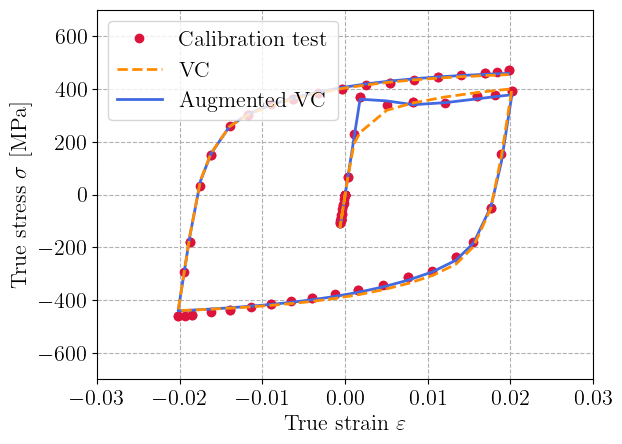

In [39]:
stress_strain_plot("Calibration", first_cycle, "calibration_first_cycle")

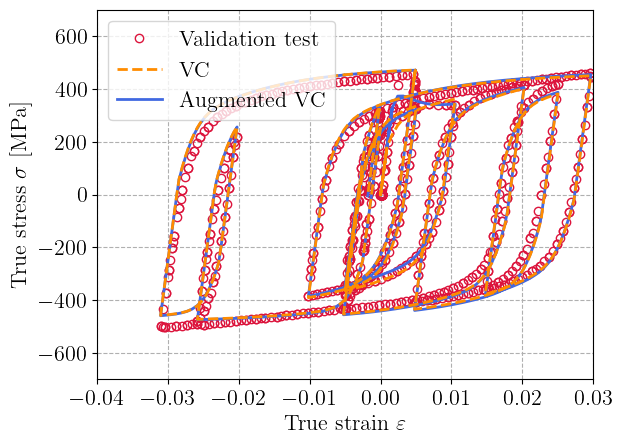

In [40]:
stress_strain_plot("Validation", slice(None), "validation")

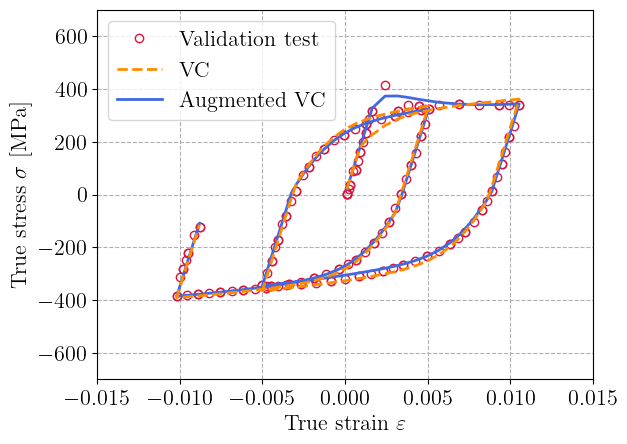

In [41]:
stress_strain_plot("Validation", first_excursions, "validation_first_excursions")

The last figure shows the size of the yield surface, $\sigma_{y,0} + R(p)$, the quantity that
enters the model, rather than the Voce part and the correction separately, over the range of $p$
reached in the calibration test.

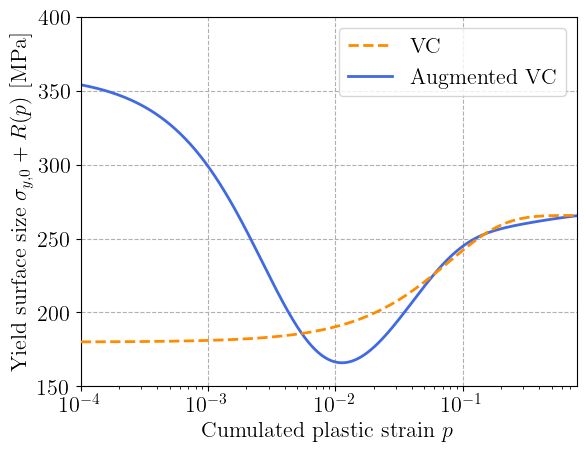

Augmented VC: yield surface size 354 MPa at p = 1e-04, minimum 166 MPa at p = 0.011
Minimum of R'(p): -74 GPa (E = 200 GPa)


In [43]:
p_calibration = float(responses["VC"]["Calibration"][1][-1])
p_plot = jnp.logspace(-4, np.log10(p_calibration), 300)
fig, ax = plt.subplots()
for name, style in STYLE.items():
    m = models[name]
    ax.semilogx(
        p_plot, m.sig0 + jax.vmap(m.isotropic)(p_plot), lw=2.0, label=name, **style
    )
ax.set_xlim(p_plot[0], p_plot[-1])
ax.set_xlabel("Cumulated plastic strain $p$")
ax.set_ylabel(r"Yield surface size $\sigma_{y,0} + R(p)$ [MPa]")
ax.legend(loc="upper right")
for ext in ("pdf", "png"):
    fig.savefig(f"hardening.{ext}", bbox_inches="tight")
plt.show()

m = models["Augmented VC"]
size = m.sig0 + jax.vmap(m.isotropic)(p_plot)
slope = jax.vmap(jax.grad(m.isotropic))(jnp.logspace(-6, np.log10(p_calibration), 3000))
print(
    f"Augmented VC: yield surface size {float(size[0]):.0f} MPa at p = {float(p_plot[0]):.0e}, "
    f"minimum {float(size.min()):.0f} MPa at p = {float(p_plot[size.argmin()]):.3f}"
)
print(
    f"Minimum of R'(p): {1e-3 * float(slope.min()):.0f} GPa (E = {1e-3 * E_nominal:.0f} GPa)"
)

The two hardening laws differ mostly at small values of $p$. The cell below splits the reduction
of $\varphi$ on the validation test according to the value of $p$ reached by the VC model at each
increment, and gives the largest stress difference between the two models.

In [13]:
eps, sig = tests["Validation"]
w = jnp.abs(jnp.diff(eps))
squared_error = {}
for name in models:
    s = responses[name]["Validation"][0]
    squared_error[name] = w * ((s[1:] - sig[1:]) ** 2 + (s[:-1] - sig[:-1]) ** 2)
gain = np.asarray(squared_error["VC"] - squared_error["Augmented VC"])
p_vc = np.asarray(responses["VC"]["Validation"][1])
for lo, hi in [(0.0, 0.01), (0.01, 0.05), (0.05, np.inf)]:
    sel = (p_vc[1:] >= lo) & (p_vc[1:] < hi)
    print(
        f"p in [{lo}, {hi}): {sel.sum():4d} increments, "
        f"{100 * gain[sel].sum() / gain.sum():5.1f}% of the reduction of phi"
    )
diff = np.abs(
    np.asarray(
        responses["VC"]["Validation"][0] - responses["Augmented VC"]["Validation"][0]
    )
)
print(
    f"Max stress difference between the two models: {diff.max():.0f} MPa, "
    f"at p = {p_vc[diff.argmax()]:.4f}"
)

p in [0.0, 0.01):  149 increments,  87.9% of the reduction of phi
p in [0.01, 0.05):  141 increments,  16.0% of the reduction of phi
p in [0.05, inf):  796 increments,  -3.8% of the reduction of phi
Max stress difference between the two models: 111 MPa, at p = 0.0011


## Discussion

The values referred to below are those printed above. They are reported and discussed in the
accompanying paper (section "Augmented hybridization on cyclic plasticity tests").

The VC model reproduces the stabilized cycles, but its initial yield stress $\sigma_{y,0}$ is well
below the stress at first yielding. With a monotonically increasing isotropic hardening,
$\sigma_{y,0}$ is a lower bound of the size of the yield surface in the subsequent cycles, and is
therefore set by the cycles rather than by first yielding. This shortcoming of the VC model for
structural steels motivated the UVC model. The initial yield stress identified with the augmented
model is consistent with first yielding.

The augmented model learns a rapid shrinkage of the yield surface after first yielding, followed
by hardening, which is the mechanism represented by the hand-crafted term of the UVC model. It
follows the first loading more closely and reduces the error measure on both the calibration test
and the held-out validation test. On the validation test, most of this reduction comes from the
increments at small $p$, where the stresses of the two models differ most; at larger values of
$p$, the two yield surfaces are close and so are the responses.

The learned law is not monotone. Its steepest negative slope, printed above, remains small
compared with the Young modulus, so that the residual of the return mapping is a strictly
decreasing function of $\Delta p$ and the update has a unique solution.

The physical parameters and the network weights are calibrated jointly through the sequence of
implicit constitutive updates of the calibration test, with exact gradients. Replacing the
implementation of the isotropic slot changes neither the return mapping nor the calibration
code.